In [156]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sksurv.datasets import load_flchain
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc

from scipy.optimize import minimize

import statsmodels.api as sm
import xgboost as xgb
import shap

# **Завантаження даних**

In [157]:
sns.set_theme(style="whitegrid", palette="muted")
X, y = load_flchain()
df_full = X.copy()

In [158]:
cols = ['age', 'sex', 'mgus', 'flc.grp', 'creatinine']
df = df_full[cols].copy()
df['death'] = y['death']   
df['futime'] = y['futime']

# **Попередній аналіз даних**

## **Початковий опис даних**

In [159]:
print("\n--- Перші 5 записів ---")
print(df.head())

print("\n--- Загальна інформація про типи даних та пропуски ---")
print(df.info())

print("\n---Базова описова статистика ---")
print(df.describe())


--- Перші 5 записів ---
    age sex mgus flc.grp  creatinine  death  futime
0  97.0   F   no      10         1.7   True    85.0
1  92.0   F   no       1         0.9   True  1281.0
2  94.0   F   no      10         1.4   True    69.0
3  92.0   F   no       9         1.0   True   115.0
4  93.0   F   no       6         1.1   True  1039.0

--- Загальна інформація про типи даних та пропуски ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7874 entries, 0 to 7873
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   age         7874 non-null   float64 
 1   sex         7874 non-null   category
 2   mgus        7874 non-null   category
 3   flc.grp     7874 non-null   category
 4   creatinine  6524 non-null   float64 
 5   death       7874 non-null   bool    
 6   futime      7874 non-null   float64 
dtypes: bool(1), category(3), float64(3)
memory usage: 216.0 KB
None

---Базова описова статистика ---
               age  

**Обробка пропусків для креатиніну**

In [160]:
missing_data = df.isnull().sum()
print("\n--- Пропущені значення ---")
print(missing_data[missing_data > 0])


--- Пропущені значення ---
creatinine    1350
dtype: int64


**Перетворення якісних ознак на бінарні змінні**

In [170]:
df_clean = df.copy()

df_clean['sex_num'] = df_clean['sex'].map({'F': 0, 'M': 1})
df_clean['mgus_num'] = df_clean['mgus'].map({'no': 0, "yes": 1})

df_clean['flc.grp'] = pd.to_numeric(df_clean['flc.grp'], errors='coerce')

df = df_clean

## **Візуалізація**

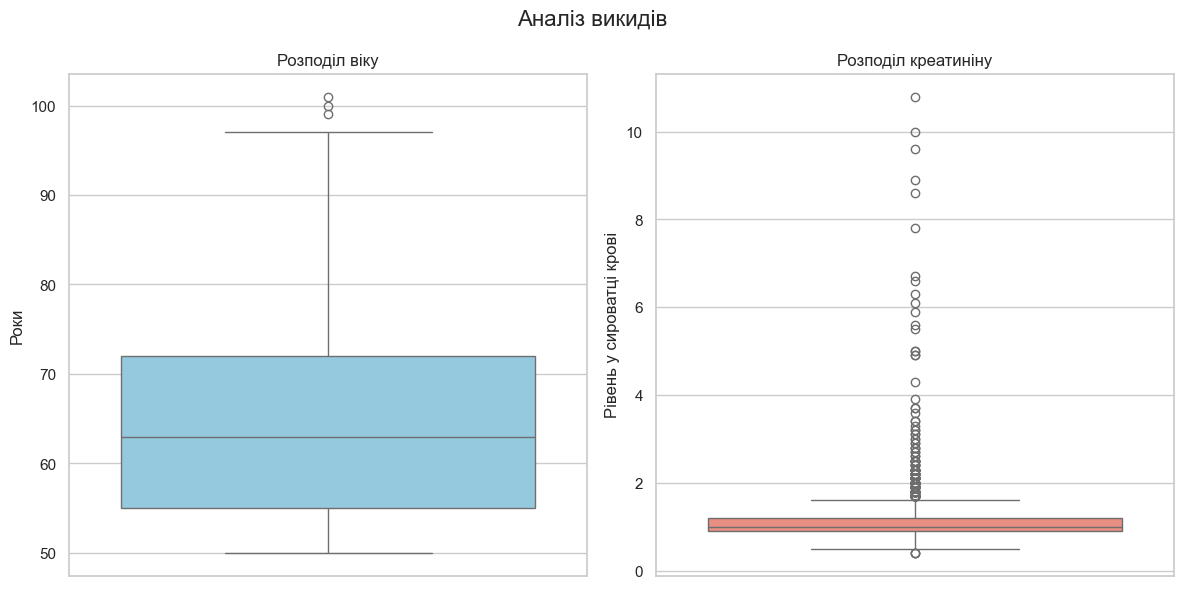

In [171]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Аналіз викидів', fontsize=16)

sns.boxplot(data=df, y='age', ax=axes[0], color='skyblue')
axes[0].set_title('Розподіл віку')
axes[0].set_ylabel('Роки')

sns.boxplot(data=df, y='creatinine', ax=axes[1], color='salmon')
axes[1].set_title('Розподіл креатиніну')
axes[1].set_ylabel('Рівень у сироватці крові')

plt.tight_layout()
plt.show()

In [172]:
def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
   
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    
    return len(outliers)

outliers_age = count_outliers(df['age'])
outliers_creatinine = count_outliers(df['creatinine'])

print(f"Кількість викидів для віку (age): {outliers_age}")
print(f"Кількість викидів для креатиніну (creatinine): {outliers_creatinine}")

Кількість викидів для віку (age): 3
Кількість викидів для креатиніну (creatinine): 220


**Графіки розподілів**

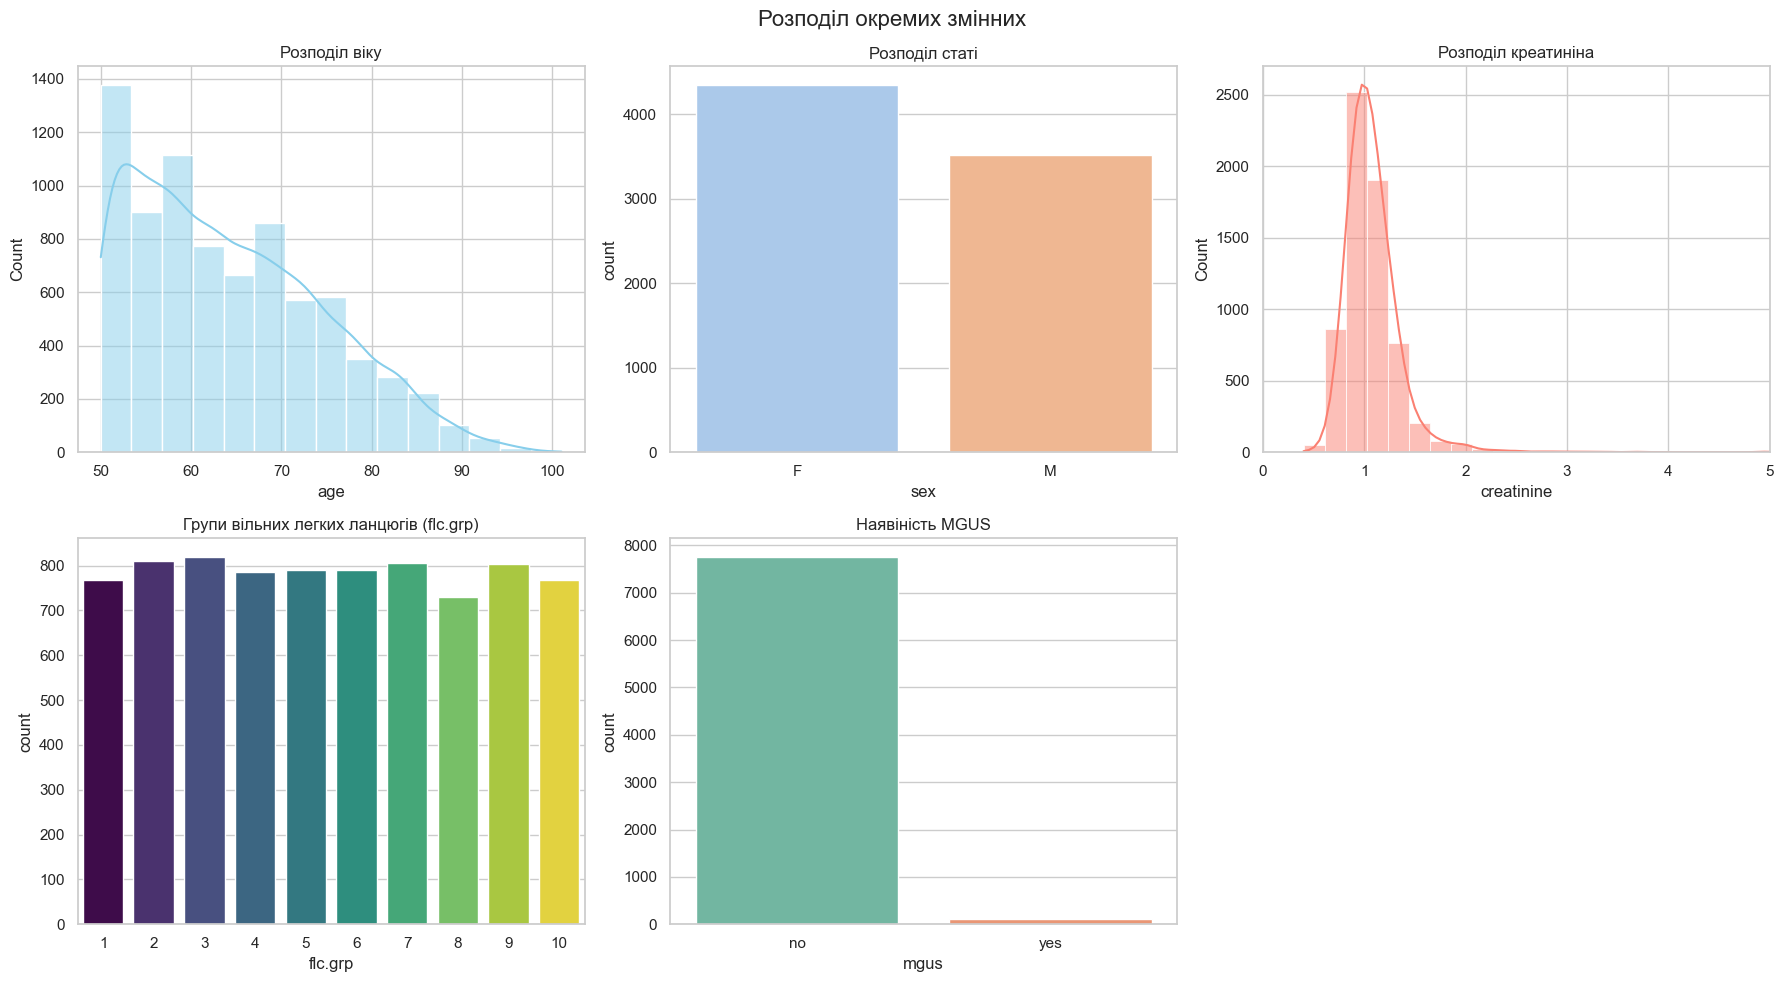

In [173]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Розподіл окремих змінних', fontsize=16)

sns.histplot(data=df, x='age', kde=True, bins=15, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Розподіл віку')

sns.countplot(data=df, x='sex', hue='sex', ax=axes[0, 1], palette='pastel', legend=False)
axes[0, 1].set_title('Розподіл статі')

sns.histplot(data=df, x='creatinine', kde=True, bins=50, ax=axes[0, 2], color='salmon')
axes[0, 2].set_xlim(0, 5)
axes[0, 2].set_title('Розподіл креатиніна')

sns.countplot(data=df, x='flc.grp', hue='flc.grp', ax=axes[1, 0], palette='viridis', legend=False)
axes[1, 0].set_title('Групи вільних легких ланцюгів (flc.grp)')

sns.countplot(data=df, x='mgus', hue='mgus', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title('Наявіність MGUS')

fig.delaxes(axes[1, 2])
plt.tight_layout()
plt.show()

In [174]:
count_mgus = df['mgus'].value_counts()

percent_mgus = df['mgus'].value_counts(normalize=True) * 100

summary_mgus = pd.DataFrame({
    'Абсолютна кількість': count_mgus,
    'Відсоток': percent_mgus.round(2)
})

print("Розподіл пацієнтів за наявністю MGUS:")
print(summary_mgus)
print("-" * 50)

count_sex = df['sex'].value_counts()
percent_sex = df['sex'].value_counts(normalize=True) * 100

summary_sex = pd.DataFrame({
    'Абсолютна кількість': count_sex,
    'Відсоток': percent_sex.round(2)
})

print("Розподіл пацієнтів за статтю:")
print(summary_sex)

Розподіл пацієнтів за наявністю MGUS:
      Абсолютна кількість  Відсоток
mgus                               
no                   7759     98.54
yes                   115      1.46
--------------------------------------------------
Розподіл пацієнтів за статтю:
     Абсолютна кількість  Відсоток
sex                               
F                   4350     55.25
M                   3524     44.75


**Залежності між змінними**

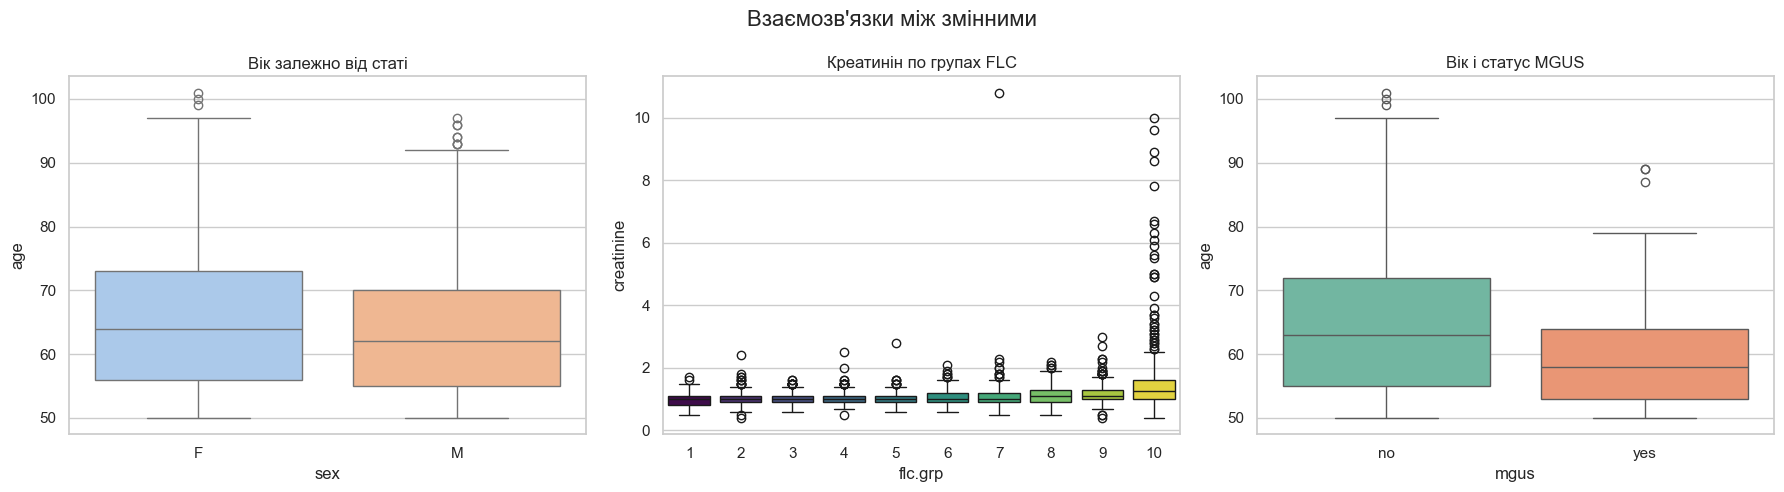

In [175]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Взаємозв\'язки між змінними', fontsize=16)

sns.boxplot(data=df, x='sex', y='age', hue='sex', ax=axes[0], palette='pastel', legend=False)
axes[0].set_title('Вік залежно від статі')

sns.boxplot(data=df, x='flc.grp', y='creatinine', hue='flc.grp', ax=axes[1], palette='viridis', legend=False)
axes[1].set_title('Креатинін по групах FLC')

sns.boxplot(data=df, x='mgus', y='age', hue='mgus', ax=axes[2], palette='Set2', legend=False)
axes[2].set_title('Вік і статус MGUS')

plt.tight_layout()
plt.show()

**Кореляційна матриця**

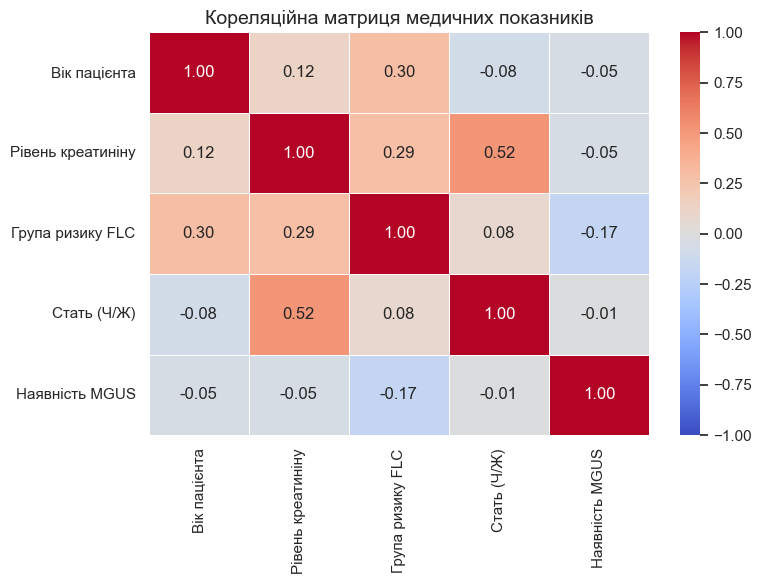

In [176]:
plt.figure(figsize=(8, 6))

num_cols = ['age', 'creatinine', 'flc.grp', 'sex_num', 'mgus_num']
corr_matrix = df[num_cols].corr(method='spearman')

pretty_labels = {
    'age': 'Вік пацієнта',
    'creatinine': 'Рівень креатиніну',
    'flc.grp': 'Група ризику FLC',
    'sex_num': 'Стать (Ч/Ж)',
    'mgus_num': 'Наявність MGUS'
}

corr_matrix = corr_matrix.rename(index=pretty_labels, columns=pretty_labels)

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', 
            vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)

plt.title('Кореляційна матриця медичних показників', fontsize=14)

plt.tight_layout() 
plt.show()

# **Таблиці смертності**

**Завантажуємо базову таблицю смертності.**

In [ ]:
df_asdr = pd.read_csv('mortality.csv', sep='\s+')
df_asdr['Age'] = df_asdr['Age'].astype(str).str.replace('+', '').astype(int)
print(df_asdr.head())

**Базові графіки смертності**

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(df_asdr['Age'], df_asdr['Male'], label='Чоловіки', color='blue')
plt.plot(df_asdr['Age'], df_asdr['Female'], label='Жінки', color='red')

plt.title('Базова смертність за віком (США, 2000-2009)')
plt.xlabel('Вік')
plt.ylabel('m_x')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(df_asdr['Age'], np.log(df_asdr['Male']), label='Чоловіки', color='blue')
plt.plot(df_asdr['Age'], np.log(df_asdr['Female']), label='Жінки', color='red')

plt.title('Логарифм базової смертності за віком (США, 2000-2009)')
plt.xlabel('Вік')
plt.ylabel('log(m_x)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

**Перетворення таблиці**

In [ ]:
df_melted = df_asdr.melt(
    id_vars=['Year', 'Age'], 
    value_vars=['Female', 'Male'], 
    var_name='sex', 
    value_name='m_x'
)
df_melted['sex'] = df_melted['sex'].map({'Female': 'F', 'Male': 'M'})
df_base_mortality = df_melted[df_melted['Age'] >= 50].copy()

df_base_mortality['log_mx'] = np.log(df_base_mortality['m_x'])

print("Таблиця підготовлена до злиття:")
print(df_base_mortality.head())

**Порівняння двох моделей смертності**

Gompertz (1825):$\mu_{x+t} = e^{\alpha + \beta(x+t)}$, 
$H_x(t) = \frac{e^{\alpha + \beta x}}{\beta} (e^{\beta t} - 1)$

 Perks (1932):$\mu_{x+t} = \frac{e^{\alpha + \beta(x+t)}}{1 + e^{\alpha + \beta(x+t)}}$, 
$H_x(t) = \frac{1}{\beta} \log \left( \frac{1 + e^{\alpha + \beta(x+t)}}{1 + e^{\alpha + \beta x}} \right)$

In [ ]:
print(df.head())

**Змінні для функції лог-правдоподібності**

In [ ]:
age = df['age'].values
t = df['futime'].values / 365.25
d = df['death'].values

Негативна лог-правдоподібність для моделі Гомпертца.

In [ ]:
def nll_gompertz(params, age, t, d):
 
    alpha, beta = params
    
    mu_xt = np.exp(alpha + beta * (age + t))
    
    H_xt = ((np.exp(beta * t) - 1) / beta) * np.exp(alpha + beta * age)
    mu_xt = np.clip(mu_xt, 1e-15, None)
    
    ll = np.sum(-H_xt + d * np.log(mu_xt))
    
    return -ll

Негативна лог-правдоподібність для моделі Перкса.

In [ ]:
def nll_perks(params, age, t, d):

    alpha, beta = params
    
    num = np.exp(alpha + beta * (age + t))
    mu_xt = num / (1 + num)
    
    val1 = 1 + np.exp(alpha + beta * (age + t))
    val2 = 1 + np.exp(alpha + beta * age)
    H_xt = (1 / beta) * np.log(val1 / val2)
    
    mu_xt = np.clip(mu_xt, 1e-15, None)
    
    ll = np.sum(-H_xt + d * np.log(mu_xt))
    return -ll

**Оптимізація логарифмічної функції правдоподібності**

In [134]:
initial_guess = [-10.0, 0.1]
bounds = [(None, None), (1e-5, None)]

res_gomp = minimize(nll_gompertz, initial_guess, args=(age, t, d), 
                    method='L-BFGS-B', bounds=bounds)

res_perks = minimize(nll_perks, initial_guess, args=(age, t, d), 
                     method='L-BFGS-B', bounds=bounds)

**Порівняння моделей за AIC**

In [135]:
k = 2
aic_gomp = 2 * k + 2 * res_gomp.fun
aic_perks = 2 * k + 2 * res_perks.fun

print("--- Результати калібрування ---")
print(f"Гомпертц: alpha = {res_gomp.x[0]:.4f}, beta = {res_gomp.x[1]:.4f} | AIC = {aic_gomp:.2f}")
print(f"Перкс:    alpha = {res_perks.x[0]:.4f}, beta = {res_perks.x[1]:.4f} | AIC = {aic_perks:.2f}")

if aic_perks < aic_gomp:
    print("\nВисновок: Модель Перкса краще описує дані (менший AIC).")
else:
    print("\nВисновок: Модель Гомпертца краще описує дані (менший AIC).")

--- Результати калібрування ---
Гомпертц: alpha = -11.4469, beta = 0.1062 | AIC = 17454.28
Перкс:    alpha = -11.8041, beta = 0.1116 | AIC = 17472.48

Висновок: Модель Гомпертца краще описує дані (менший AIC).


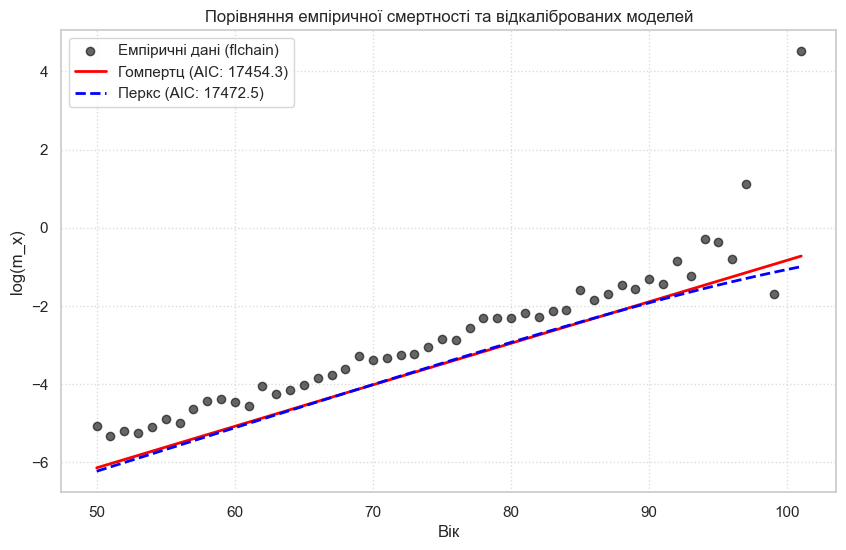

In [136]:
df_empirical = pd.DataFrame({
    'age': np.floor(age).astype(int), 
    'exposure': t, 
    'deaths': d
})

grouped = df_empirical.groupby('age').sum()

grouped['m_x'] = grouped['deaths'] / grouped['exposure']

grouped = grouped[(grouped['deaths'] > 0) & (grouped['exposure'] > 0)]

age_range = np.linspace(grouped.index.min(), grouped.index.max(), 100)

alpha_g, beta_g = res_gomp.x
mu_gomp = np.exp(alpha_g + beta_g * age_range)

alpha_p, beta_p = res_perks.x
num_p = np.exp(alpha_p + beta_p * age_range)
mu_perks = num_p / (1 + num_p)

plt.figure(figsize=(10, 6))

plt.scatter(grouped.index, np.log(grouped['m_x']), 
            color='black', label='Емпіричні дані (flchain)', alpha=0.6, marker='o')

plt.plot(age_range, np.log(mu_gomp), 
         color='red', label=f'Гомпертц (AIC: {aic_gomp:.1f})', linewidth=2)
plt.plot(age_range, np.log(mu_perks), 
         color='blue', linestyle='--', label=f'Перкс (AIC: {aic_perks:.1f})', linewidth=2)

plt.title('Порівняння емпіричної смертності та відкаліброваних моделей')
plt.xlabel('Вік')
plt.ylabel('log(m_x)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.show()

**Калібрування національних таблиць смертності.**

In [137]:
print(df.head())

    age sex mgus  flc.grp  creatinine  death  futime sex_num mgus_num  Age  \
0  97.0   F   no       10         1.7   True    85.0       0        0   97   
1  92.0   F   no        1         0.9   True  1281.0       0        0   92   
2  94.0   F   no       10         1.4   True    69.0       0        0   94   
3  92.0   F   no        9         1.0   True   115.0       0        0   92   
4  93.0   F   no        6         1.1   True  1039.0       0        0   93   

   entry_age       t_i   exit_age  d_i  
0       97.0  0.232717  97.232717    1  
1       92.0  3.507187  95.507187    1  
2       94.0  0.188912  94.188912    1  
3       92.0  0.314853  92.314853    1  
4       93.0  2.844627  95.844627    1  


In [138]:
print(df_base_mortality.head())

         Year  Age sex       m_x    log_mx
50  2000-2009   50   F  0.003271 -5.722660
51  2000-2009   51   F  0.003492 -5.657281
52  2000-2009   52   F  0.003778 -5.578561
53  2000-2009   53   F  0.004036 -5.512501
54  2000-2009   54   F  0.004359 -5.435513


In [139]:
df['Age'] = df['age'].astype(int)

df_merged = pd.merge(
    df,
    df_base_mortality[['Age', 'sex', 'm_x', 'log_mx']], 
    on=['Age', 'sex'], 
    how='left'
)

df_merged = df_merged.rename(columns={
    'm_x': 'base_mx',
    'log_mx': 'base_log_mx'
})

print(df_merged.head())

    age sex mgus  flc.grp  creatinine  death  futime sex_num mgus_num  Age  \
0  97.0   F   no       10         1.7   True    85.0       0        0   97   
1  92.0   F   no        1         0.9   True  1281.0       0        0   92   
2  94.0   F   no       10         1.4   True    69.0       0        0   94   
3  92.0   F   no        9         1.0   True   115.0       0        0   92   
4  93.0   F   no        6         1.1   True  1039.0       0        0   93   

   entry_age       t_i   exit_age  d_i   base_mx  base_log_mx  
0       97.0  0.232717  97.232717    1  0.313446    -1.160128  
1       92.0  3.507187  95.507187    1  0.191004    -1.655461  
2       94.0  0.188912  94.188912    1  0.235285    -1.446958  
3       92.0  0.314853  92.314853    1  0.191004    -1.655461  
4       93.0  2.844627  95.844627    1  0.212953    -1.546684  


In [140]:
age = df_merged['age'].values
t = df_merged['futime'].values / 365.25  
d = df_merged['death'].values
base_mx = df_merged['base_mx'].values 

def nll_table_calibration(params, age, t, d, base_mx):
    alpha_adj, beta_adj = params
    
    mu_xt = base_mx * np.exp(alpha_adj + beta_adj * (age + t))
    
    H_xt = base_mx * ((np.exp(alpha_adj + beta_adj * (age + t)) - np.exp(alpha_adj + beta_adj * age)) / beta_adj)

    mu_xt = np.clip(mu_xt, 1e-15, None)
    
    ll = np.sum(-H_xt + d * np.log(mu_xt))
    return -ll

initial_guess = [0.0, 0.001] 
bounds = [(None, None), (1e-6, None)]

res_calib = minimize(nll_table_calibration, initial_guess, 
                     args=(age, t, d, base_mx), 
                     method='L-BFGS-B', bounds=bounds)

alpha_adj, beta_adj = res_calib.x

print("--- Параметри калібрування таблиці США під flchain ---")
print(f"Alpha (базовий зсув) = {alpha_adj:.4f}")
print(f"Beta (віковий нахил) = {beta_adj:.4f}")

--- Параметри калібрування таблиці США під flchain ---
Alpha (базовий зсув) = -1.0619
Beta (віковий нахил) = 0.0190


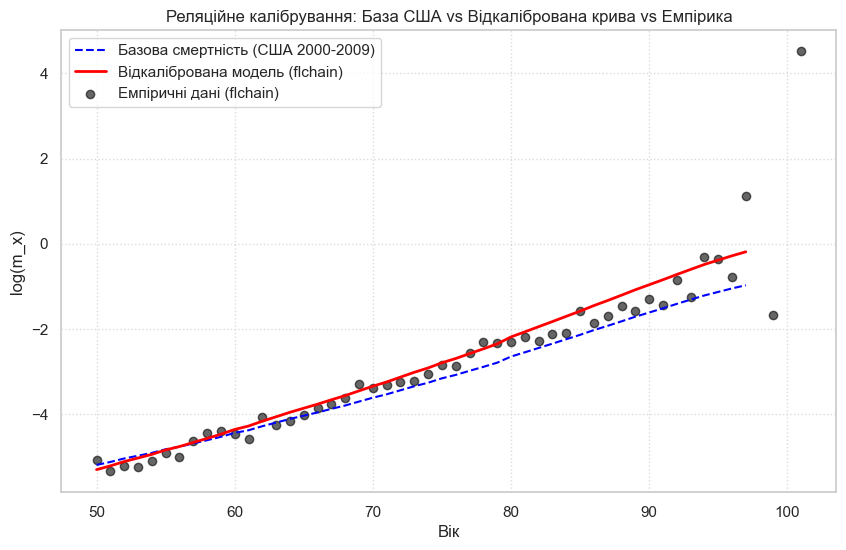

In [141]:
df_plot = df_merged[df_merged['sex'] == 'M'].drop_duplicates(subset=['Age']).sort_values('Age')

calibrated_mu = df_plot['base_mx'] * np.exp(alpha_adj + beta_adj * df_plot['Age'])

plt.figure(figsize=(10, 6))

plt.plot(df_plot['Age'], np.log(df_plot['base_mx']), 
         label='Базова смертність (США 2000-2009)', color='blue', linestyle='--')

plt.plot(df_plot['Age'], np.log(calibrated_mu), 
         label=f'Відкалібрована модель (flchain)', color='red', linewidth=2)

plt.scatter(grouped.index, np.log(grouped['m_x']), 
            label='Емпіричні дані (flchain)', color='black', alpha=0.6, marker='o')

plt.title('Реляційне калібрування: База США vs Відкалібрована крива vs Емпірика')
plt.xlabel('Вік')
plt.ylabel('log(m_x)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)

plt.show()

In [142]:
print(calibrated_mu)

6198    0.005021
6200    0.005487
6197    0.006065
6195    0.006594
6194    0.007183
5485    0.007974
5486    0.008626
5480    0.009496
5481    0.010441
5488    0.011520
3503    0.012881
3500    0.013954
3498    0.015643
3508    0.017348
3499    0.019271
2391    0.021199
2385    0.023302
2390    0.025831
2388    0.028497
2389    0.031848
1982    0.035530
1981    0.039193
1987    0.043945
1980    0.049193
1984    0.054473
762     0.061545
763     0.067962
764     0.076245
767     0.085249
784     0.095781
102     0.112735
110     0.126898
104     0.143270
107     0.161559
103     0.182737
113     0.206295
106     0.235004
127     0.264806
125     0.299877
119     0.340465
80      0.382849
94      0.430831
88      0.486926
79      0.548210
82      0.616630
81      0.755173
96      0.829504
dtype: float64


In [178]:
df_merged['calibrated_mu'] = df_merged['base_mx'] * np.exp(alpha_adj + beta_adj * df_merged['Age'])

df_merged['offset'] = np.log(df_merged['calibrated_mu'])

print(df_merged.head())

    age sex mgus  flc.grp  creatinine  death  futime sex_num mgus_num  Age  \
0  97.0   F   no       10         1.7   True    85.0       0        0   97   
1  92.0   F   no        1         0.9   True  1281.0       0        0   92   
2  94.0   F   no       10         1.4   True    69.0       0        0   94   
3  92.0   F   no        9         1.0   True   115.0       0        0   92   
4  93.0   F   no        6         1.1   True  1039.0       0        0   93   

   entry_age       t_i   exit_age  d_i   base_mx  base_log_mx  calibrated_mu  \
0       97.0  0.232717  97.232717    1  0.313446    -1.160128       0.686392   
1       92.0  3.507187  95.507187    1  0.191004    -1.655461       0.380307   
2       94.0  0.188912  94.188912    1  0.235285    -1.446958       0.486646   
3       92.0  0.314853  92.314853    1  0.191004    -1.655461       0.380307   
4       93.0  2.844627  95.844627    1  0.212953    -1.546684       0.432154   

     offset  
0 -0.376306  
1 -0.966777  
2 -0.720

In [144]:
df_merged.to_csv('current_df.csv', index=False)

# ПОБУДОВА МОДЕЛЕЙ GLM І GBM

In [187]:
df = pd.read_csv('current_df.csv')

features = ['age', 'sex_num', 'mgus_num', 'creatinine', 'flc.grp']
X = df[features].copy()
y = df['d_i'] 

offset_uncalibrated = df['base_log_mx'] 
offset_calibrated = df['offset']

Розбиття на підвибірки тренування і тестування.

In [188]:
X_train, X_test, y_train, y_test, off_uncal_train, off_uncal_test, off_cal_train, off_cal_test = train_test_split(
    X, y, offset_uncalibrated, offset_calibrated, 
    test_size=0.2, random_state=42, stratify=y
)

Обробка пропусків

In [189]:
imputer = KNNImputer(n_neighbors=5)
X_train_im = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_im = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

X_train_glm = sm.add_constant(X_train_im)
X_test_glm = sm.add_constant(X_test_im)

Функція для тренування та оцінки GLM

In [191]:
def train_evaluate_glm(X_tr, y_tr, X_te, y_te, off_tr, off_te, title):
    model = sm.GLM(y_tr, X_tr, family=sm.families.Poisson(link=sm.families.links.Log()), offset=off_tr).fit()
    preds = model.predict(X_te, offset=off_te)
    
    auc = roc_auc_score(y_te, preds)
    print(f"{title} | ROC-AUC: {auc:.4f} | Gini: {2*auc-1:.4f}")
    return model

Функція для тренування та оцінки XGBoost

In [190]:
def train_evaluate_xgb(X_tr, y_tr, X_te, y_te, off_tr, off_te, title):
    dtrain = xgb.DMatrix(X_tr, label=y_tr)
    dtrain.set_base_margin(off_tr)
    
    dtest = xgb.DMatrix(X_te, label=y_te)
    dtest.set_base_margin(off_te)
    
    params = {'objective': 'count:poisson', 'eval_metric': 'auc', 'learning_rate': 0.05, 
              'max_depth': 4, 'subsample': 0.8, 'colsample_bytree': 0.8, 'seed': 42}
    
    model = xgb.train(params, dtrain, num_boost_round=150)
    preds = model.predict(dtest)
    
    auc = roc_auc_score(y_te, preds)
    print(f"{title} | ROC-AUC: {auc:.4f} | Gini: {2*auc-1:.4f}")
    return model

Результати моделей за різних умов:

In [193]:
# ---------------------------------------------------------
# 4. ЕКСПЕРИМЕНТ 1: Невідкалібрована таблиця (base_log_mx)
# ---------------------------------------------------------
print("=== ЕКСПЕРИМЕНТ 1: Національна таблиця США (без калібрування) ===")
glm_uncal = train_evaluate_glm(X_train_glm, y_train, X_test_glm, y_test, off_uncal_train, off_uncal_test, "GLM (Uncalibrated)")
xgb_uncal = train_evaluate_xgb(X_train_im, y_train, X_test_im, y_test, off_uncal_train, off_uncal_test, "XGB (Uncalibrated)")

# ---------------------------------------------------------
# 5. ЕКСПЕРИМЕНТ 2: Відкалібрована таблиця (Ваш MLE offset)
# ---------------------------------------------------------
print("\n=== ЕКСПЕРИМЕНТ 2: Відкалібрована таблиця (MLE flchain) ===")
glm_cal = train_evaluate_glm(X_train_glm, y_train, X_test_glm, y_test, off_cal_train, off_cal_test, "GLM (Calibrated)  ")
xgb_cal = train_evaluate_xgb(X_train_im, y_train, X_test_im, y_test, off_cal_train, off_cal_test, "XGB (Calibrated)  ")

# Перевіряємо гіпотезу про те, що коефіцієнти віку впали після калібрування
print("\n--- Зміна коефіцієнта AGE у GLM ---")
print(f"До калібрування (Uncalibrated): {glm_uncal.params['age']:.5f} (p-value: {glm_uncal.pvalues['age']})")
print(f"Після калібрування (Calibrated): {glm_cal.params['age']:.5f} (p-value: {glm_cal.pvalues['age']})")

=== ЕКСПЕРИМЕНТ 1: Національна таблиця США (без калібрування) ===
GLM (Uncalibrated) | ROC-AUC: 0.8338 | Gini: 0.6675
XGB (Uncalibrated) | ROC-AUC: 0.8362 | Gini: 0.6725

=== ЕКСПЕРИМЕНТ 2: Відкалібрована таблиця (MLE flchain) ===
GLM (Calibrated)   | ROC-AUC: 0.8338 | Gini: 0.6675
XGB (Calibrated)   | ROC-AUC: 0.8361 | Gini: 0.6723

--- Зміна коефіцієнта AGE у GLM ---
До калібрування (Uncalibrated): -0.02592 (p-value: 1.1935318571952397e-30)
Після калібрування (Calibrated): -0.04495 (p-value: 1.3315139906345893e-88)


Аналіз важливості ознак (SHAP)

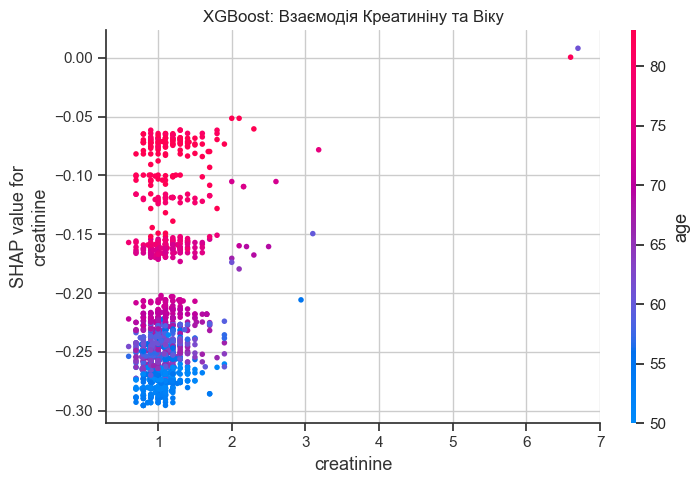

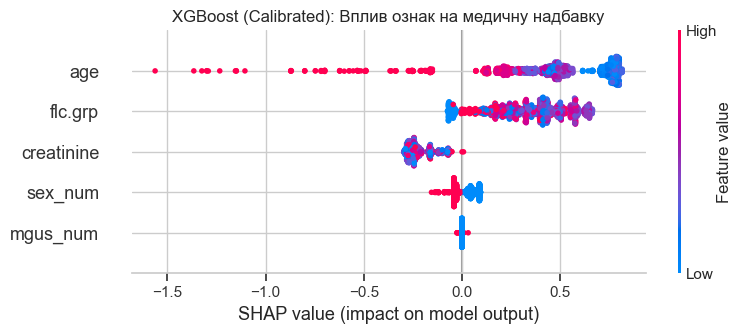

In [195]:
xplainer = shap.TreeExplainer(xgb_cal)
shap_values = explainer.shap_values(X_test_im)

shap.dependence_plot("creatinine", shap_values, X_test_im, interaction_index="age", show=False)
plt.title("XGBoost: Взаємодія Креатиніну та Віку")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, X_test_im, show=False)
plt.title("XGBoost (Calibrated): Вплив ознак на медичну надбавку")
plt.tight_layout()
plt.show()